# EDA Role 3: The Power Cost of the AI Race

Notebook ini menghitung semua angka KPI dari data warehouse PostgreSQL db_project3 (galaxy schema, diisi DAG Airflow).

Asumsi yang dipakai:
- tanggal acuan 15 Nov 2026 (baris setelah tanggal ini adalah rencana pembangunan)
- utilisasi 70% (diuji juga 50% dan 90%)
- intensitas grid tahun 2025: negara bagian untuk data center di AS, negara untuk lokasi lain
- emisi dihitung dari total power, karena listrik untuk pendingin juga menghasilkan emisi

## 1. Read Data


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine

TANGGAL_ACUAN = "2026-11-15"
UTILISASI = 0.7
TG = "Total generation"

# koneksi ke data warehouse PostgreSQL (hasil load DAG), kredensial dari file .env
load_dotenv()
engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('PG_USER')}:{os.getenv('PG_PASSWORD')}"
    f"@{os.getenv('PG_HOST', 'localhost')}:{os.getenv('PG_PORT', '5432')}/{os.getenv('PG_DB', 'db_project3')}"
)

def baca(tabel, **kw):
    """Ambil satu tabel dari data warehouse PostgreSQL."""
    return pd.read_sql(f"SELECT * FROM {tabel}", engine, **kw)

ddc = baca("dim_data_center")
dco = baca("dim_country")
fi  = baca("fact_infrastructure", parse_dates=["record_date"])
fgc = baca("fact_grid_country")
fgs = baca("fact_grid_state")

print("sumber data: data warehouse PostgreSQL", os.getenv("PG_DB"))
for nama, df in [("dim_data_center", ddc), ("fact_infrastructure", fi), ("fact_grid_country", fgc), ("fact_grid_state", fgs)]:
    print(f"{nama:22s} {df.shape}")

sumber data: data warehouse PostgreSQL db_project3
dim_data_center        (96, 7)
fact_infrastructure    (575, 10)
fact_grid_country      (15359, 6)
fact_grid_state        (3643, 6)


**INSIGHT:** <br>
Data terbaca lengkap: 96 data center dan 575 baris riwayat pembangunan. Data dibaca langsung dari tabel dim dan fact di data warehouse.

## 2. Introduction

Melihat isi tabel, jumlah nilai kosong, dan pembagian data nyata vs rencana.

In [ ]:
display(fi.head())
print(fi.isna().sum())
print(fi["is_actual"].value_counts())
print("data center per negara:")
print(ddc["country_name"].value_counts())

,datacenter_name,record_date,construction_status,buildings_operational,it_power_mw,total_power_mw,pue,h100e,annual_operating_cost_usd,is_actual
0,AWS Berwick,2021-07-01,Land clearing begins. [Talen Energy](https://w...,0.0,0.0,0.0,NaN,0.000000,0.0,True
1,AWS Berwick,2023-01-17,[Cumulus](https://www.prnewswire.com/news-rele...,0.0,0.0,0.0,NaN,0.000000,0.0,True
2,AWS Berwick,2024-03-04,[AWS](https://www.sec.gov/Archives/edgar/data/...,0.0,0.0,0.0,NaN,0.000000,0.0,True
3,AWS Berwick,2024-06-01,Building 1 fit out and related construction be...,0.0,0.0,0.0,NaN,0.000000,0.0,True
4,AWS Berwick,2025-09-09,Building 1 operational estimate. According to ...,1.0,47.0,66.0,1.4043,35320.869126,42394000.0,True


datacenter_name                0
record_date                    0
construction_status            0
buildings_operational          0
it_power_mw                    0
total_power_mw                 0
pue                          212
h100e                          0
annual_operating_cost_usd      0
is_actual                      0
dtype: int64
is_actual
True     481
False     94
Name: count, dtype: int64
data center per negara:
country_name
United States           77
China                    5
Malaysia                 4
Norway                   2
Sweden                   1
United Kingdom           1
Finland                  1
Iceland                  1
United Arab Emirates     1
Indonesia                1
Australia                1
Portugal                 1
Name: count, dtype: int64


**INSIGHT:** <br>
Dari 575 baris, 481 adalah data nyata dan 94 adalah rencana pembangunan sampai 2030. Rencana dipisahkan supaya tidak ikut terhitung. <br>
Kolom PUE kosong di 212 baris karena data center di baris itu belum beroperasi (IT power 0), jadi bukan data yang hilang. Amerika Serikat mendominasi dengan 77 dari 96 lokasi.

## 3. Latest Snapshot per Data Center

Satu data center punya banyak baris (riwayat pembangunan). Untuk menghitung kondisi pada satu tanggal, ambil baris terakhir sebelum tanggal itu.
Dibuat sebagai fungsi karena dipakai berkali-kali (kondisi sekarang, akhir tiap tahun, dan uji utilisasi).

**Cara hitung:**
- Snapshot = baris terakhir tiap data center dengan record_date ≤ tanggal acuan
- Energi per tahun (TWh) = total power (MW) × 8.760 jam × utilisasi ÷ 1.000.000
- Emisi per tahun (MtCO2e) = energi (TWh) × intensitas grid (g/kWh) ÷ 1.000

In [ ]:
gs = fgs[(fgs.electricity_source == TG) & (fgs.year == 2025)].set_index("state_code")
gc = fgc[(fgc.electricity_source == TG) & (fgc.year == 2025)].set_index("country_name")

def snapshot(tanggal, util=UTILISASI):
    """Kondisi semua data center pada satu tanggal.

    Ambil baris terakhir tiap data center yang record_date-nya <= tanggal,
    lalu tambahkan intensitas grid, energi per tahun, dan emisi per tahun.

    tanggal : contoh "2026-11-15"
    util    : utilisasi, default 0.7
    """
    s = (fi[fi.record_date <= tanggal].sort_values("record_date")
           .groupby("datacenter_name").tail(1)
           .merge(ddc, on="datacenter_name"))
    s["intensity_gco2e_kwh"] = s.state_code.map(gs.intensity_gco2e_kwh).fillna(s.country_name.map(gc.intensity_gco2e_kwh))
    s["energy_twh"] = s.total_power_mw * 8760 * util / 1e6
    s["emissions_mtco2e"] = s.energy_twh * s.intensity_gco2e_kwh / 1000
    return s

snap = snapshot(TANGGAL_ACUAN)          # semua 96 lokasi
op = snap[snap.it_power_mw > 0].copy()  # yang sudah beroperasi
print(len(snap), len(op), "| intensitas kosong:", snap.intensity_gco2e_kwh.isna().sum())

96 76 | intensitas kosong: 0


**INSIGHT:** <br>
Dari 96 data center, 76 sudah beroperasi (IT power lebih dari 0). Semua data center berhasil mendapat nilai intensitas grid, jadi tidak ada yang terlewat saat menghitung emisi.

## 4. Key Metrics (KQ2 & KQ3)

Angka ringkasan dari kondisi terakhir 96 data center: kapasitas, listrik untuk pendingin, energi, dan emisi per tahun.

**Cara hitung:**
- Overhead (MW) = total power − IT power
- PUE = total power ÷ IT power
- Intensitas tertimbang = Σ(total power × intensitas) ÷ Σ total power
- Emisi per MW = total emisi (ton) ÷ total power (MW)

In [ ]:
kpi = pd.Series({
    "Jumlah data center": len(snap),
    "Sudah beroperasi": len(op),
    "IT power (MW)": snap.it_power_mw.sum(),
    "Total power (MW)": snap.total_power_mw.sum(),
    "Overhead pendingin dll. (MW)": (op.total_power_mw - op.it_power_mw).sum(),
    "Median PUE": op.pue.median(),
    "PUE kuartil terbaik": op.pue.quantile(0.25),
    "Energi per tahun (TWh)": op.energy_twh.sum(),
    "Emisi per tahun (MtCO2e)": op.emissions_mtco2e.sum(),
    "Intensitas tertimbang (g/kWh)": (op.total_power_mw * op.intensity_gco2e_kwh).sum() / op.total_power_mw.sum(),
    "Emisi per MW (tCO2e/MW/tahun)": op.emissions_mtco2e.sum() * 1e6 / op.total_power_mw.sum(),
})
kpi.round(2)

Jumlah data center                  96.00
Sudah beroperasi                    76.00
IT power (MW)                    15122.03
Total power (MW)                 19467.21
Overhead pendingin dll. (MW)      4345.18
Median PUE                           1.30
PUE kuartil terbaik                  1.20
Energi per tahun (TWh)             119.37
Emisi per tahun (MtCO2e)            52.21
Intensitas tertimbang (g/kWh)      437.34
Emisi per MW (tCO2e/MW/tahun)     2681.76
dtype: float64

**INSIGHT:**<br>
Sekitar 22% listrik data center (4.345 MW) habis untuk pendingin dan kebutuhan gedung, bukan untuk server. <br>
Dengan utilisasi 70%, seluruh data center ini memakai 119,4 TWh listrik dan menghasilkan 52,2 MtCO2e per tahun, atau rata-rata sekitar 2.680 tCO2e per MW.

## 5. Yearly Growth (KQ1 & KQ2)

Kondisi diambil di akhir tiap tahun, lalu dijumlahkan. Intensitas grid menggunakan 2025 untuk semua tahun sebagai acuan.

**Cara hitung:** <br>
snapshot diambil tiap 31 Desember (2026 memakai 15 November), lalu IT power, H100e, energi, dan emisi dijumlahkan per tahun.

,it_mw,h100e,twh,mt,h100e_juta
year,,,,,
2021,48.00,7882.77,0.35,0.11,0.01
2022,67.00,14350.68,0.50,0.20,0.01
2023,401.00,178102.09,3.12,1.17,0.18
2024,2015.00,1190882.20,15.62,6.32,1.19
2025,6756.73,5917929.32,52.81,22.81,5.92
2026,15122.03,15768419.86,119.37,52.21,15.77


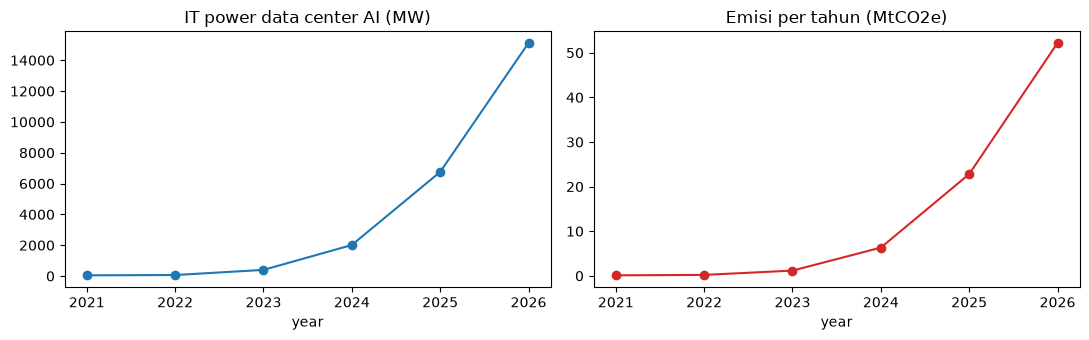

In [ ]:
tanggal = {2021: "2021-12-31", 2022: "2022-12-31", 2023: "2023-12-31",
           2024: "2024-12-31", 2025: "2025-12-31", 2026: TANGGAL_ACUAN}
rows = []
for th, tgl in tanggal.items():
    s = snapshot(tgl)
    rows.append(s.assign(year=th))
trend_site = pd.concat(rows)
trend = trend_site.groupby("year").agg(it_mw=("it_power_mw", "sum"), h100e=("h100e", "sum"),
                                       twh=("energy_twh", "sum"), mt=("emissions_mtco2e", "sum"))
trend["h100e_juta"] = trend.h100e / 1e6
display(trend.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
trend.it_mw.plot(ax=ax[0], marker="o", title="IT power data center AI (MW)")
trend.mt.plot(ax=ax[1], marker="o", color="tab:red", title="Emisi per tahun (MtCO2e)")
plt.tight_layout(); plt.show()

**INSIGHT:**<br>
*Menjawab Key Question 2:* <br>
KQ 2 : Seberapa besar konsumsi listrik dan estimasi emisi karbon data center AI dunia setiap tahun sejak 2021, dan bagaimana trennya?


Konsumsi listrik naik dari 0,3 TWh (2021) menjadi 119,4 TWh (2026), dan emisinya dari 0,1 menjadi 52,2 MtCO2e per tahun. Lonjakan terbesar terjadi di dua tahun terakhir: emisi 2026 lebih dari dua kali lipat emisi 2025 (22,8 Mt). Catatan: dataset hanya melacak data center yang sekarang sudah besar, jadi angka tahun-tahun awal cenderung lebih kecil dari kondisi sebenarnya.

## 6. Dominant Companies (KQ1)

Berikut pengecekan untuk perusahaan Data Center AI yang mendominasi saat ini.


**Cara hitung:** <br>
porsi perusahaan (%) = IT power milik perusahaan ÷ total IT power × 100

,it_mw,persen
owner_name,,
Google,3179.0,21.0
Meta,2335.0,15.4
Amazon,1870.0,12.4
Unknown,1869.0,12.4
Microsoft,1519.0,10.0
SpaceXAI,1303.0,8.6


Top 3 menguasai 48.8 %


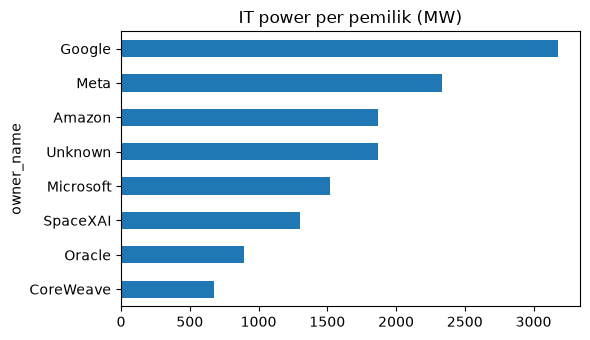

In [ ]:
owner = snap.groupby("owner_name").it_power_mw.sum().sort_values(ascending=False)
owner_pct = (owner / owner.sum() * 100).round(1)
display(pd.DataFrame({"it_mw": owner.round(0), "persen": owner_pct}).head(6))
print("Top 3 menguasai", owner_pct.head(3).sum(), "%")

owner.head(8).sort_values().plot.barh(figsize=(6, 3.5), title="IT power per pemilik (MW)")
plt.tight_layout(); plt.show()

**INSIGHT:**<br>
*Menjawab Key Question 1:* <br>
Bagaimana tren pertumbuhan kapasitas listrik (MW) dan kapasitas komputasi (H100e) data center AI dunia sejak 2021, dan perusahaan mana yang paling besar kontribusinya?

Kapasitas IT naik dari 48 MW (akhir 2021) menjadi 15.122 MW (November 2026), dan kapasitas komputasi dari sekitar 0,01 juta menjadi 15,77 juta H100e. <br>
Tiga perusahaan terbesar adalah Google (3.179 MW), Meta (2.335 MW), dan Amazon (1.870 MW), yang bersama-sama menguasai 48,8% kapasitas. Ada 1.869 MW yang pemiliknya tidak diketahui (Unknown), jadi porsi perusahaan besar sebenarnya bisa lebih tinggi.

## 7. Efficiency (KQ3)

Membandingkan PUE, komputasi per MW, emisi per MW, dan biaya operasional dari 76 data center yang sudah beroperasi.


**Cara hitung:**
- Komputasi per MW = H100e ÷ IT power (MW)
- Biaya per MW = biaya operasional per tahun (USD) ÷ 1.000.000 ÷ total power (MW)
- Emisi per MW = emisi (ton) ÷ total power (MW)

,pue,h100e_per_mw,opex_juta_usd_per_mw,emisi_t_per_mw
count,76.00,76.00,76.00,76.00
mean,1.29,1045.56,0.70,2469.75
std,0.09,305.79,0.05,890.31
min,1.00,188.67,0.60,170.20
25%,1.20,856.27,0.66,2108.93
50%,1.30,1137.21,0.69,2326.20
75%,1.38,1208.79,0.75,3239.40
max,1.52,1929.79,0.90,4325.06


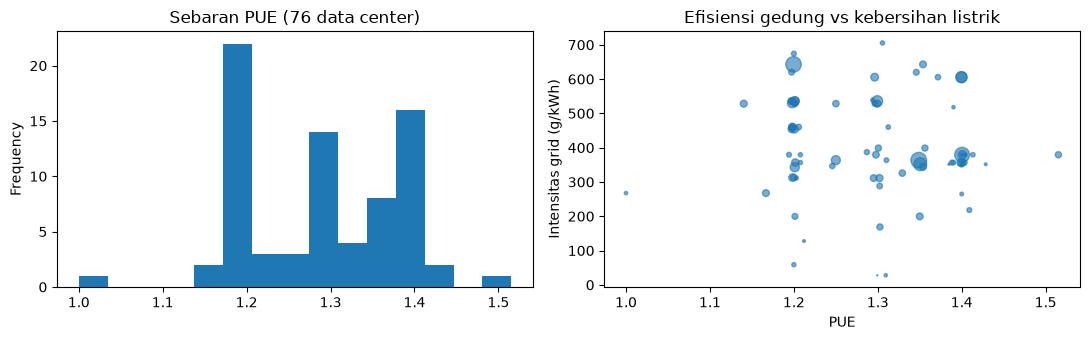

In [ ]:
op["h100e_per_mw"] = op.h100e / op.it_power_mw
op["opex_juta_usd_per_mw"] = op.annual_operating_cost_usd / 1e6 / op.total_power_mw
op["emisi_t_per_mw"] = op.emissions_mtco2e * 1e6 / op.total_power_mw
display(op[["pue", "h100e_per_mw", "opex_juta_usd_per_mw", "emisi_t_per_mw"]].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
op.pue.plot.hist(ax=ax[0], bins=15, title="Sebaran PUE (76 data center)")
ax[1].scatter(op.pue, op.intensity_gco2e_kwh, s=op.total_power_mw / 10, alpha=.6)
ax[1].set(xlabel="PUE", ylabel="Intensitas grid (g/kWh)", title="Efisiensi gedung vs kebersihan listrik")
plt.tight_layout(); plt.show()

**INSIGHT:**<br>
*Menjawab Key Question 3:* <br>
Seberapa efisien data center AI, dilihat dari PUE, kapasitas komputasi per MW, emisi, dan biaya operasional?

PUE hampir semua data center ada di 1,2–1,4 (median 1,30), jadi efisiensi gedungnya mirip. Setiap MW IT menghasilkan sekitar 1.137 H100e, dengan biaya operasional sekitar 0,69 juta USD per MW per tahun. Yang paling berbeda justru emisinya: dari sekitar 170 tCO2e per MW di Islandia sampai 4.300 tCO2e per MW di Batam. Artinya, emisi lebih ditentukan oleh sumber listrik di lokasi daripada efisiensi gedung.

## 8. Regional Grid Burden (KQ4)

Porsi listrik data center dibanding seluruh listrik yang dibangkitkan di wilayah itu.
Untuk AS dihitung per negara bagian, karena angka nasional menyembunyikan beban lokal.

**Cara hitung:** <br>
beban (%) = energi data center di wilayah itu (TWh) ÷ total pembangkitan listrik wilayah itu tahun 2025 (TWh) × 100

,total_dc_mw,total_dc_twh_per_year,total_generation_twh,burden_percentage
state_code,,,,
TN,1815.0,11.13,74.77,14.88
NE,843.0,5.17,39.85,12.97
IN,1485.0,9.11,110.24,8.26
VA,1398.0,8.57,107.03,8.01
OH,1795.0,11.01,146.87,7.49
ID,198.0,1.21,21.06,5.77


,total_dc_mw,total_dc_twh_per_year,total_generation_twh,burden_percentage
country_name,,,,
Malaysia,1722.37,10.56,210.37,5.02
United States,16201.80,99.35,4519.79,2.20
Finland,90.00,0.55,82.48,0.67
Portugal,40.00,0.25,51.12,0.48
United Kingdom,124.00,0.76,293.66,0.26
Iceland,6.64,0.04,18.27,0.22
Norway,55.00,0.34,160.85,0.21
Australia,57.00,0.35,285.92,0.12
Indonesia,94.00,0.58,528.21,0.11


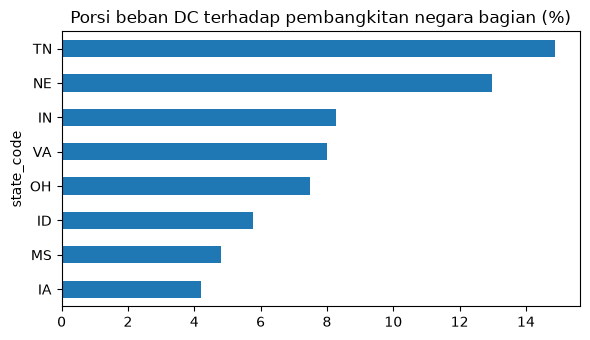

In [ ]:
gen_state = gs.generation_twh
gen_country = gc.generation_twh

state = op.groupby("state_code").agg(total_dc_mw=("total_power_mw", "sum"), total_dc_twh_per_year=("energy_twh", "sum"))
state["total_generation_twh"] = gen_state.reindex(state.index)
state["burden_percentage"] = state.total_dc_twh_per_year / state.total_generation_twh * 100

country = op.groupby("country_name").agg(total_dc_mw=("total_power_mw", "sum"), total_dc_twh_per_year=("energy_twh", "sum"))
country["total_generation_twh"] = gen_country.reindex(country.index)
country["burden_percentage"] = country.total_dc_twh_per_year / country.total_generation_twh * 100

display(state.sort_values("burden_percentage", ascending=False).head(6).round(2))
display(country.sort_values("burden_percentage", ascending=False).round(2))

state.burden_percentage.sort_values().tail(8).plot.barh(figsize=(6, 3.5), title="Porsi beban DC terhadap pembangkitan negara bagian (%)")
plt.tight_layout(); plt.show()

**INSIGHT:**<br>
*Menjawab Key Question 4:* <br>
Di wilayah mana beban listrik data center AI paling besar dibanding total pembangkitan listrik wilayah tersebut?

Tennessee 14,9%, Nebraska 13,0%, Indiana 8,3%, sedangkan secara nasional AS hanya 2,2%. Artinya, angka nasional menyembunyikan beban di tingkat lokal: di beberapa negara bagian, data center AI sudah memakai sekitar sepertujuh listrik yang dibangkitkan. Di level negara, porsi tertinggi ada di Malaysia (5,0%).

## 9. Ideal vs Non-Ideal Locations (KQ5)

Membandingkan dengan rata-rata intensitas listrik dunia 2025.
Kategori yang dipakai: di bawah 200 g/kWh = ideal, di atas rata-rata dunia = tidak ideal, di antaranya = menengah.

**Cara hitung:** <br>
intensitas negara = Σ(total power × intensitas) ÷ Σ total power, supaya data center yang lebih besar lebih berpengaruh.

Rata-rata dunia: 460 g/kWh


,operating_facilities,total_dc_mw,median_pue,emissions_mtco2e,grid_intensity_g_kwh,kategori
country_name,,,,,,
Iceland,1,6.64,1.30,0.00,27.76,Ideal (grid bersih)
Norway,1,55.00,1.31,0.01,28.05,Ideal (grid bersih)
Finland,1,90.00,1.20,0.03,58.75,Ideal (grid bersih)
Portugal,1,40.00,1.21,0.03,127.80,Ideal (grid bersih)
United Kingdom,1,124.00,1.41,0.17,218.00,Menengah
United States,60,16201.80,1.30,41.50,417.68,Menengah
Australia,1,57.00,1.39,0.18,517.96,Tidak ideal (di atas rata-rata dunia)
China,5,1076.40,1.25,3.49,528.28,Tidak ideal (di atas rata-rata dunia)
Malaysia,4,1722.37,1.39,6.40,605.55,Tidak ideal (di atas rata-rata dunia)


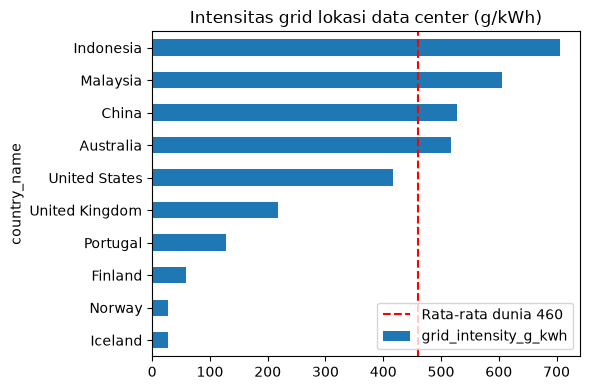

In [ ]:
if "World" in gc.index:
    world = gc.loc["World", "intensity_gco2e_kwh"]
else:
    world = 460.1
print("Rata-rata dunia:", round(world), "g/kWh")

op["mw_x_intensity"] = op.total_power_mw * op.intensity_gco2e_kwh
reg = op.groupby("country_name").agg(
    operating_facilities=("datacenter_name", "count"),
    total_dc_mw=("total_power_mw", "sum"),
    median_pue=("pue", "median"),
    mw_x_intensity=("mw_x_intensity", "sum"),
    emissions_mtco2e=("emissions_mtco2e", "sum"),
)
reg["grid_intensity_g_kwh"] = reg.mw_x_intensity / reg.total_dc_mw   # rata-rata tertimbang MW
reg = reg.drop(columns="mw_x_intensity").sort_values("grid_intensity_g_kwh")

def kategori(i):
    """
    Kelompokkan intensitas grid: < 200 ideal, > rata-rata dunia tidak ideal, sisanya menengah.
    """
    if i < 200: return "Ideal (grid bersih)"
    if i > world: return "Tidak ideal (di atas rata-rata dunia)"
    return "Menengah"
reg["kategori"] = reg.grid_intensity_g_kwh.apply(kategori)
display(reg.round(2))

ax = reg.grid_intensity_g_kwh.plot.barh(figsize=(6, 4), title="Intensitas grid lokasi data center (g/kWh)")
ax.axvline(world, color="red", ls="--", label=f"Rata-rata dunia {world:.0f}")
ax.legend(); plt.tight_layout(); plt.show()

**INSIGHT:**<br>
*Menjawab Key Question 5:* <br>
Negara atau wilayah mana yang paling dan paling tidak ideal untuk membangun data center AI, berdasarkan intensitas karbon listrik, beban terhadap pembangkitan listrik, efisiensi, dan biaya operasional?

**Ideal:** Norwegia, Islandia (28), Finlandia (59), Portugal (128). <br>
**Tidak ideal:** Australia, China, Malaysia, Indonesia (705). <br>

Penilaian memakai intensitas grid karena faktor lainnya mirip antarnegara: median PUE 1,20–1,41 dan biaya operasional sekitar 0,6–0,9 juta USD per MW. Sebaliknya, intensitas grid berbeda sampai 25 kali (28 vs 705 g/kWh). Beban terhadap pembangkitan dibahas terpisah di KQ4.

## 10. Utilization Sensitivity (Why 70%?)

Data tidak punya angka utilisasi, jadi hasil dihitung ulang dengan 50% dan 90% untuk melihat seberapa besar pengaruh asumsi ini.

**Cara hitung:** <br>
rumus energi dan emisi sama dengan bagian 3, hanya angka utilisasinya diganti 50% dan 90%.

In [ ]:
for u in [0.5, 0.7, 0.9]:
    s = snapshot(TANGGAL_ACUAN, util=u)
    s = s[s.it_power_mw > 0]
    print(f"utilisasi {u:.0%}: {s.energy_twh.sum():6.1f} TWh   {s.emissions_mtco2e.sum():5.1f} MtCO2e")

utilisasi 50%:   85.3 TWh    37.3 MtCO2e
utilisasi 70%:  119.4 TWh    52.2 MtCO2e
utilisasi 90%:  153.5 TWh    67.1 MtCO2e


**INSIGHT:**<br>
50%: 85 TWh / 37 Mt <br>
70%: 119 TWh / 52 Mt <br>
90%: 154 TWh / 67 Mt <br>
Utilisasi tidak tersedia di data, jadi 70% dipakai sebagai titik tengah. Di skenario 50% maupun 90%, emisinya tetap puluhan juta ton per tahun (37–67 Mt), jadi kesimpulannya tidak berubah.

## 11. Indonesia Spotlight

Melihat posisi satu-satunya data center Indonesia di dataset dibanding lokasi lain.

In [ ]:
op[op.country_name == "Indonesia"][["datacenter_name", "owner_name", "it_power_mw", "total_power_mw", "pue",
                                    "intensity_gco2e_kwh", "energy_twh", "emissions_mtco2e"]].round(3)

,datacenter_name,owner_name,it_power_mw,total_power_mw,pue,intensity_gco2e_kwh,energy_twh,emissions_mtco2e
27,Oracle Batam,Oracle,72.0,94.0,1.306,705.326,0.576,0.407


**INSIGHT:** <br>
Oracle Batam: 72 MW IT, 94 MW total, PUE 1,31, grid 705 g/kWh, sekitar 0,41 MtCO2e per tahun. <br>
Ini satu-satunya data center Indonesia di dataset, tapi emisi per MW-nya paling tinggi dari 76 data center yang beroperasi, karena grid Indonesia paling kotor (705 g/kWh).

## 12. Key Findings

1. Kapasitas listrik data center AI yang tercatat naik dari 48 MW pada akhir 2021 menjadi 15.122 MW pada November 2026, dan lebih dari separuhnya (8.365 MW) bertambah sepanjang 2026. Emisinya ikut naik dari 0,1 menjadi 52,2 MtCO2e per tahun. Artinya, tambahan listrik dalam setahun terakhir saja (66,6 TWh) hampir menyamai seluruh listrik yang dibangkitkan Tennessee dalam setahun (74,8 TWh). (KQ1, KQ2)<br>
2. Indonesia baru punya satu data center AI di dataset (Oracle Batam, 94 MW), tapi emisinya per MW paling tinggi dari 76 lokasi yang beroperasi: sekitar 4.300 tCO2e per MW per tahun, karena intensitas grid Indonesia 705 g/kWh atau 1,5 kali rata-rata dunia. Kalau ekspansi data center di Indonesia tidak disertai listrik yang lebih bersih, setiap MW baru akan menyumbang emisi lebih besar dibanding negara lain. (KQ5) <br>
3. Secara nasional, data center AI hanya memakai 2,2% listrik AS. Tapi di Tennessee porsinya 14,9% dan di Nebraska 13%. Artinya, dampak data center AI terhadap jaringan listrik perlu dinilai per wilayah, bukan per negara. Pembuat kebijakan di wilayah seperti Tennessee dan Nebraska perlu mensyaratkan tambahan pembangkit atau listrik bersih sebelum memberi izin data center baru. (KQ4)

## 13. Export for Google Sheets (3 Dashboard Tabs)

Tiga file ini menjadi sumber data dashboard (Google Sheets → Tableau Public). Angka totalnya sudah dicocokkan dengan view SQL di data warehouse (15.122 MW, 119,4 TWh, 52,2 MtCO2e, Tennessee 14,9%).

In [ ]:
cols_site = ["datacenter_name", "country_name", "state_code", "owner_name", "record_date", "it_power_mw",
             "total_power_mw", "pue", "h100e", "annual_operating_cost_usd", "intensity_gco2e_kwh",
             "energy_twh", "emissions_mtco2e"]
snap[cols_site].to_csv("dash_site.csv", index=False)

dash_trend = (trend_site.groupby(["year", "country_name"])
              .agg(dc_total_power_mw=("total_power_mw", "sum"), total_it_power_mw=("it_power_mw", "sum"),
                   total_h100_equivalents=("h100e", "sum"), estimated_dc_consumption_twh=("energy_twh", "sum"),
                   estimated_dc_emissions_mtco2e=("emissions_mtco2e", "sum"))
              .reset_index())
dash_trend.to_csv("dash_trend.csv", index=False)

def ringkas(df, kolom, level, gen):
    """
    Ringkas data per wilayah (negara bagian atau negara) untuk tab dash_region.
    Hanya menghitung data center yang total power-nya lebih dari 0.
    """
    d = df[df.total_power_mw > 0].assign(mw_x_i=lambda x: x.total_power_mw * x.intensity_gco2e_kwh)
    g = d.groupby(kolom)
    out = pd.DataFrame({
        "total_dc_mw": g.total_power_mw.sum(),
        "total_dc_twh_per_year": g.energy_twh.sum(),
        "median_pue": g.pue.median(),
        "grid_intensity_g_kwh": g.mw_x_i.sum() / g.total_power_mw.sum(),
        "emissions_mtco2e": g.emissions_mtco2e.sum(),
    })
    out["total_generation_twh"] = gen.reindex(out.index)
    out["burden_percentage"] = out.total_dc_twh_per_year / out.total_generation_twh * 100
    out["world_intensity_g_kwh"] = world
    return out.reset_index().rename(columns={kolom: "region"}).assign(region_level=level)

dash_region = pd.concat([ringkas(snap.dropna(subset=["state_code"]), "state_code", "state", gen_state),
                         ringkas(snap, "country_name", "country", gen_country)])
dash_region = dash_region[["region_level", "region", "total_dc_mw", "total_dc_twh_per_year", "total_generation_twh",
                           "burden_percentage", "median_pue", "grid_intensity_g_kwh", "emissions_mtco2e",
                           "world_intensity_g_kwh"]]
dash_region.to_csv("dash_region.csv", index=False)
print(len(snap), len(dash_trend), len(dash_region))

96 51 37


Impor ketiga file ke satu Google Sheets sebagai 3 tab.